# Roasting a batch

Every other notebook here simulates something the project made up. This one simulates a
machine that exists: a **Loring S15**, fifteen kilograms of green coffee at a time, which
roasted five batches on the evening of 30 July 2026 while a bridge logged it over Modbus
every one and a half seconds.

So there is a right answer, and it was not computed — it was measured. The figures below
put the model's curve on top of the roaster's own bean probe and leave the gap visible.

One of the four states is the thermocouple itself, and that matters more than it sounds. A
bean probe is a lump of steel with its own heat capacity, so for the first minute of a
roast it is not measuring the coffee so much as catching up with it — which is the whole
explanation of the *turning point*, the dive every roaster watches for in the first
seconds.

This notebook is meant to be **run**. The figures are drawn by matplotlib when the site is
built; the sliders at the end need a live kernel, so on this page they are a snapshot of
their last state. The file is attached — [roasting.ipynb](roasting.ipynb) — but it reads
the model from `examples/`, so it wants a checkout rather than a bare download:

```bash
git clone https://gitlab.com/cardona-oss/modelica && cd modelica
pip install "modelica[sim]" matplotlib ipywidgets
jupyter lab docs/notebooks/roasting.ipynb
```

The measurement it checks against is carried inline, a little further down. The roast logs
live in a different repository and this page does not want to depend on one.

In [1]:
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np

# The model comes from `examples/` in the repository rather than from a string in here: a copy
# pasted into a notebook is a copy that goes stale, and the reason this page is executed when the
# site is built is that it then cannot show output from a model the project does not have.
root = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "examples" / "models").is_dir()), None
)
if root is None:
    message = (
        "This notebook reads its model from `examples/` in the modelica repository. "
        "Run it from a checkout:\n"
        "    git clone https://gitlab.com/cardona-oss/modelica\n"
        "    cd modelica && jupyter lab docs/notebooks/"
    )
    raise RuntimeError(message)

SURFACE, INK, MUTED, LINE = "#fcfcfb", "#0b0b0b", "#52514e", "#d4d3cd"
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"

mpl.rcParams.update(
    {
        "figure.figsize": (8.4, 3.4),
        "figure.dpi": 110,
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "axes.edgecolor": LINE,
        "axes.labelcolor": MUTED,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.titlelocation": "left",
        "axes.titlepad": 10,
        "axes.titlesize": 11,
        "grid.color": "#e8e7e2",
        "grid.linewidth": 0.8,
        "lines.linewidth": 2.0,
        "legend.frameon": False,
        "text.color": INK,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "font.size": 10,
    }
)
%config InlineBackend.figure_formats = ["svg"]


def minutes(ax):
    """Roasts are read in minutes and seconds, not in seconds."""
    ax.set_xlabel("time from charge (min)")
    ax.xaxis.set_major_formatter(lambda s, _: f"{int(s // 60)}:{int(s % 60):02d}")
    ax.xaxis.set_major_locator(mpl.ticker.MultipleLocator(120))


def label(ax, x, y, text, colour, dy=0):
    """Direct labels, one per series.

    Four series here sit under 3:1 against the surface, so every one of them is named on the
    plot rather than left to colour alone.
    """
    ax.annotate(
        text,
        xy=(x, y),
        xytext=(6, dy),
        textcoords="offset points",
        color=colour,
        fontsize=9,
        va="center",
    )


SETTLED = 120.0
"""Seconds after the charge beyond which the probe's arrival transient is over.

Before it the thermocouple is still catching up with the bean mass that buried it, and on
a batch charged straight off a drop its reading at the mark is contaminated. The model
covers that stretch -- it is what `T_probe` is for -- but it is where the disagreement
lives, so the figures report either side of it separately.
"""

"Seconds after the charge beyond which the probe's arrival transient is over.\n\nBefore it the thermocouple is still catching up with the bean mass that buried it, and on\na batch charged straight off a drop its reading at the mark is contaminated. The model\ncovers that stretch -- it is what `T_probe` is for -- but it is where the disagreement\nlives, so the figures report either side of it separately.\n"

## The machine

Four states, and each is a different kind of thing:

| state | what it is |
|---|---|
| `T_mach` | everything hot that is not coffee — steel, lining, recirculated air |
| `T_bean` | the coffee |
| `T_probe` | the thermocouple *in* the coffee, which is not the same as the coffee |
| `m_w` | the water still in the beans |

The burner pushes heat into the machine, the machine leaks some to the room and hands the
rest to the coffee, the coffee boils water off once it is past 100 °C, and the probe trails
along behind.

`moisture` is a **parameter**, not a fitted number, and it does real work: the charge's heat
capacity is `m_dry*cp_dry + m_w*cp_water`, so it falls as the batch dries. `m_dry` and the
starting water are computed *from* it — a parameter bound to an expression over other
parameters, resolved to a number before any integration happens.

The nine-level chain on `burner` is not invented. It is this batch's own recorded gas
trace, reduced to the steps worth carrying.

In [2]:
print((root / "examples" / "models" / "RoastingMachine.mo").read_text())

model RoastingMachine "A Loring S15 coffee roaster over one batch -- gas on a clock, water on a threshold"
  parameter Real T_amb(unit = "K") = 293.15 "The roastery, 20 degC";
  parameter Real m_green(unit = "kg") = 15 "The charge. Rated, not weighed";
  parameter Real moisture = 0.115 "Water in the green coffee, by mass";
  parameter Real m_dry(unit = "kg") = m_green * (1 - moisture) "Dry matter";
  parameter Real cp_dry(unit = "J/(kg.K)") = 1800 "Dry coffee";
  parameter Real cp_water(unit = "J/(kg.K)") = 4186 "Water";
  parameter Real L(unit = "J/kg") = 2260000.0 "Latent heat of vaporisation";
  parameter Real k_dry(unit = "1/(K.s)") = 4.67e-6 "Drying rate above boiling";
  parameter Real C_mach(unit = "J/K") = 530000.0 "Machine hot mass: steel, lining, loop air";
  parameter Real UA(unit = "W/K") = 261 "Air-to-bean coupling over the whole bed";
  parameter Real G_loss(unit = "W/K") = 259 "Loop to ambient: the bleed and the shell";
  parameter Real Q_max(unit = "W") = 139000.0 "Burn

## One batch

`parse` → `flatten` → `causalize` → `simulate`, the same four calls as every other model in
the corpus. What comes back is fourteen and a half minutes of roast.

In [3]:
from modelica.lang import parse
from modelica.sim import causalize, flatten, simulate

flat = flatten(
    [parse((root / "examples" / "models" / "RoastingMachine.mo").read_text())], "RoastingMachine"
)
system = causalize(flat)

STOP = 863.6
result = simulate(system, stop=STOP, tolerance=1e-10, points=900)

end = result.at(STOP)
print(f"states   {sorted(system.states)}")
print(f"events   {len(result.events)}")
print(f"drop     the probe reads {end['probe']:.1f} degC; the coffee is at {end['bean']:.1f} degC")
print(f"water    {end['m_w']:.3f} kg left, {end['loss']:.2f} % of the charge driven off as steam")

states   ['T_bean', 'T_mach', 'T_probe', 'm_w']
events   9
drop     the probe reads 213.5 degC; the coffee is at 213.7 degC
water    1.324 kg left, 2.67 % of the charge driven off as steam


## Two kinds of event in one model

Nine events, and they are not the same species.

**Eight are on the clock.** A gas step fires because it is twenty past ten — the condition
is on `time` itself, so every one of those instants is known before the integration starts.

**One is on the state.** `evap` is zero until the beans pass 100 °C, and *when* that happens
depends on the trajectory. Nobody knows it in advance; the solver has to hunt for it, the
way `DrainingTank` hunts for the moment a tank runs dry. It lands at 111.4 s.

Having both kinds in one model is why this example is in the corpus. The burner gets its own
panel rather than a second y-axis — per cent and degrees are different measures and do not
belong on one scale.

In [4]:
for event in result.events:
    print(f"  t = {event.time:6.1f} s  ({event.time / 60:5.2f} min)   {event.cause}")

  t =   66.7 s  ( 1.11 min)   time < 66.7 changed
  t =   93.0 s  ( 1.55 min)   time < 93.0 changed
  t =  111.4 s  ( 1.86 min)   T_bean > 373.15 changed
  t =  526.9 s  ( 8.78 min)   time < 526.9 changed
  t =  618.0 s  (10.30 min)   time < 618.0 changed
  t =  688.5 s  (11.47 min)   time < 688.5 changed
  t =  714.6 s  (11.91 min)   time < 714.6 changed
  t =  754.4 s  (12.57 min)   time < 754.4 changed
  t =  780.8 s  (13.01 min)   time < 780.8 changed


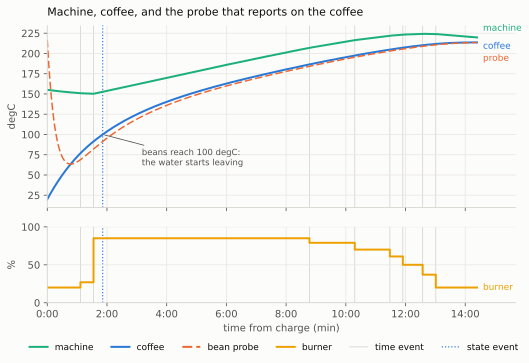

In [5]:
t = result.time
bean = result.values[result.names.index("bean")]
probe = result.values[result.names.index("probe")]
mach = result.values[result.names.index("T_mach")] - 273.15
gas = result.values[result.names.index("burner")]
water = result.values[result.names.index("m_w")]

fig, (top, bottom) = plt.subplots(
    2, 1, figsize=(8.4, 5.0), sharex=True, height_ratios=[2.4, 1], gridspec_kw={"hspace": 0.15}
)

top.plot(t, mach, color=AQUA)
top.plot(t, bean, color=BLUE)
top.plot(t, probe, color=ORANGE, linewidth=1.5, linestyle=(0, (5, 2)))
label(top, t[-1], mach[-1], "machine", AQUA, dy=9)
label(top, t[-1], bean[-1], "coffee", BLUE, dy=-4)
label(top, t[-1], probe[-1], "probe", ORANGE, dy=-16)
top.set_title("Machine, coffee, and the probe that reports on the coffee")
top.set_ylabel("degC")
top.set_xlim(0, STOP * 1.09)

bottom.plot(t, gas, color=YELLOW, drawstyle="steps-post")
label(bottom, t[-1], gas[-1], "burner", YELLOW)
bottom.set_ylabel("%")
bottom.set_ylim(0, 100)
minutes(bottom)

boil = [e.time for e in result.events if "T_bean" in e.cause]  # the one state event
for event in result.events:
    on_state = event.time in boil
    for ax in (top, bottom):
        ax.axvline(
            event.time,
            color=BLUE if on_state else LINE,
            linewidth=1.2 if on_state else 0.8,
            linestyle=":" if on_state else "-",
            zorder=0,
        )
top.annotate(
    "beans pass the drying onset:\nthe water starts leaving",
    xy=(boil[0], 40.0),
    xytext=(215, 38),
    fontsize=8.5,
    color=MUTED,
    arrowprops={"arrowstyle": "-", "color": MUTED, "linewidth": 0.8},
)

fig.legend(
    handles=[
        mpl.lines.Line2D([], [], color=AQUA, label="machine"),
        mpl.lines.Line2D([], [], color=BLUE, label="coffee"),
        mpl.lines.Line2D([], [], color=ORANGE, linestyle=(0, (5, 2)), label="bean probe"),
        mpl.lines.Line2D([], [], color=YELLOW, label="burner"),
        mpl.lines.Line2D([], [], color=LINE, linewidth=0.8, label="time event"),
        mpl.lines.Line2D([], [], color=BLUE, linewidth=1.2, linestyle=":", label="state event"),
    ],
    loc="lower center",
    ncol=6,
    bbox_to_anchor=(0.5, -0.05),
    fontsize=9,
)
plt.show()

## What the roaster actually read

Here is the measurement. Five batches, downsampled to fifteen-second spacing and carried
inline so this page owes nothing to another repository: for each one, the gas trace the
machine followed and what its bean probe reported.

In [6]:
BATCHES = [
    # batch 1: 14.39 min, 9 gas steps
    {
        "mach0": 237.38,
        "stop": 863.63,
        "turn": 46.75,
        "gas": [
            (0.0, 20.0),
            (66.7, 27.01),
            (93.0, 84.97),
            (526.9, 79.29),
            (618.0, 70.0),
            (688.5, 61.46),
            (714.6, 50.0),
            (754.4, 37.42),
            (780.8, 20.0),
        ],
        "bt": [
            (0.0, 216.83),
            (15.0, 102.84),
            (30.0, 70.45),
            (45.0, 64.49),
            (60.0, 67.25),
            (75.0, 72.73),
            (90.0, 79.94),
            (105.0, 87.57),
            (120.0, 94.87),
            (135.0, 101.41),
            (150.0, 107.61),
            (165.0, 113.39),
            (180.0, 118.96),
            (195.0, 123.84),
            (210.0, 127.71),
            (225.0, 131.7),
            (240.0, 135.39),
            (255.0, 138.73),
            (270.0, 141.76),
            (285.0, 144.94),
            (300.0, 147.65),
            (315.0, 150.33),
            (330.0, 153.13),
            (345.0, 155.73),
            (360.0, 158.27),
            (375.0, 161.0),
            (390.0, 163.16),
            (405.0, 165.6),
            (420.0, 168.11),
            (435.0, 170.18),
            (450.0, 172.4),
            (465.0, 174.37),
            (480.0, 176.53),
            (495.0, 178.58),
            (510.0, 180.56),
            (525.0, 182.76),
            (540.0, 184.74),
            (555.0, 186.74),
            (570.0, 188.74),
            (585.0, 190.57),
            (600.0, 192.48),
            (615.0, 194.79),
            (630.0, 196.86),
            (645.0, 198.89),
            (660.0, 201.03),
            (675.0, 203.12),
            (690.0, 205.32),
            (705.0, 207.26),
            (720.0, 208.83),
            (735.0, 210.03),
            (750.0, 211.07),
            (765.0, 211.94),
            (780.0, 212.28),
            (795.0, 212.68),
            (810.0, 213.5),
            (825.0, 214.15),
            (840.0, 214.68),
            (855.0, 215.56),
            (863.6, 216.06),
        ],
    },
    # batch 2: 13.90 min, 28 gas steps
    {
        "mach0": 234.67,
        "stop": 833.7,
        "turn": 43.83,
        "gas": [
            (0.0, 20.0),
            (50.0, 74.5),
            (76.2, 27.19),
            (102.2, 50.99),
            (128.1, 100.0),
            (154.2, 78.47),
            (190.9, 84.56),
            (227.6, 90.58),
            (256.8, 98.53),
            (283.0, 92.51),
            (308.8, 100.0),
            (334.7, 93.85),
            (360.8, 99.59),
            (387.0, 93.21),
            (413.1, 100.0),
            (486.5, 94.91),
            (512.8, 100.0),
            (538.9, 91.92),
            (565.2, 78.18),
            (591.3, 64.21),
            (623.3, 54.44),
            (654.0, 49.06),
            (680.3, 38.88),
            (706.3, 67.48),
            (732.5, 55.43),
            (759.5, 50.11),
            (785.2, 37.54),
            (811.0, 20.0),
        ],
        "bt": [
            (0.0, 192.17),
            (15.0, 100.61),
            (30.0, 68.4),
            (45.0, 62.76),
            (60.0, 66.1),
            (75.0, 73.07),
            (90.0, 80.12),
            (105.0, 86.27),
            (120.0, 92.48),
            (135.0, 99.1),
            (150.0, 105.64),
            (165.0, 111.43),
            (180.0, 116.5),
            (195.0, 121.2),
            (210.0, 125.92),
            (225.0, 129.94),
            (240.0, 133.96),
            (255.0, 137.77),
            (270.0, 141.22),
            (285.0, 144.62),
            (300.0, 147.44),
            (315.0, 150.52),
            (330.0, 153.85),
            (345.0, 156.5),
            (360.0, 159.14),
            (375.0, 161.82),
            (390.0, 164.49),
            (405.0, 167.17),
            (420.0, 169.58),
            (435.0, 172.13),
            (450.0, 174.57),
            (465.0, 177.0),
            (480.0, 179.52),
            (495.0, 181.95),
            (510.0, 184.26),
            (525.0, 186.59),
            (540.0, 189.03),
            (555.0, 191.16),
            (570.0, 193.3),
            (585.0, 195.54),
            (600.0, 197.32),
            (615.0, 198.64),
            (630.0, 200.58),
            (645.0, 202.18),
            (660.0, 203.49),
            (675.0, 204.98),
            (690.0, 206.33),
            (705.0, 207.51),
            (720.0, 209.04),
            (735.0, 210.66),
            (750.0, 211.87),
            (765.0, 212.57),
            (780.0, 213.68),
            (795.0, 214.65),
            (810.0, 215.5),
            (825.0, 216.35),
            (833.7, 216.94),
        ],
    },
    # batch 3: 14.27 min, 24 gas steps
    {
        "mach0": 234.23,
        "stop": 856.39,
        "turn": 44.26,
        "gas": [
            (0.0, 20.0),
            (50.3, 87.48),
            (75.8, 20.0),
            (101.3, 30.99),
            (127.0, 100.0),
            (152.6, 92.63),
            (178.2, 79.76),
            (205.3, 69.06),
            (230.9, 100.0),
            (273.0, 92.63),
            (301.7, 99.23),
            (429.5, 91.52),
            (455.1, 100.0),
            (504.6, 93.56),
            (530.1, 99.29),
            (555.8, 74.15),
            (581.3, 79.76),
            (606.9, 53.97),
            (632.6, 44.26),
            (658.3, 51.46),
            (683.7, 43.97),
            (709.4, 60.76),
            (735.1, 34.97),
            (786.8, 22.45),
        ],
        "bt": [
            (0.0, 171.56),
            (15.0, 90.21),
            (30.0, 64.74),
            (45.0, 61.55),
            (60.0, 65.8),
            (75.0, 73.38),
            (90.0, 80.39),
            (105.0, 86.41),
            (120.0, 92.25),
            (135.0, 98.54),
            (150.0, 105.35),
            (165.0, 111.05),
            (180.0, 116.35),
            (195.0, 121.25),
            (210.0, 125.76),
            (225.0, 129.51),
            (240.0, 133.19),
            (255.0, 137.1),
            (270.0, 140.84),
            (285.0, 144.41),
            (300.0, 147.29),
            (315.0, 150.17),
            (330.0, 153.32),
            (345.0, 156.22),
            (360.0, 158.83),
            (375.0, 161.53),
            (390.0, 164.25),
            (405.0, 166.9),
            (420.0, 169.52),
            (435.0, 172.23),
            (450.0, 174.46),
            (465.0, 176.73),
            (480.0, 179.22),
            (495.0, 181.66),
            (510.0, 184.04),
            (525.0, 186.28),
            (540.0, 188.73),
            (555.0, 191.02),
            (570.0, 192.94),
            (585.0, 195.19),
            (600.0, 196.97),
            (615.0, 198.83),
            (630.0, 200.38),
            (645.0, 201.69),
            (660.0, 203.4),
            (675.0, 204.85),
            (690.0, 206.14),
            (705.0, 207.46),
            (720.0, 208.56),
            (735.0, 209.44),
            (750.0, 210.11),
            (765.0, 210.82),
            (780.0, 211.61),
            (795.0, 212.41),
            (810.0, 212.96),
            (825.0, 213.83),
            (840.0, 214.58),
            (855.0, 215.47),
            (856.4, 215.72),
        ],
    },
    # batch 4: 14.18 min, 21 gas steps
    {
        "mach0": 233.63,
        "stop": 851.0,
        "turn": 42.26,
        "gas": [
            (0.0, 20.0),
            (49.7, 100.0),
            (75.4, 20.0),
            (101.0, 43.74),
            (126.6, 100.0),
            (152.1, 87.89),
            (177.7, 74.21),
            (203.3, 89.23),
            (228.7, 97.07),
            (344.5, 90.7),
            (370.0, 96.37),
            (539.3, 89.12),
            (565.0, 79.88),
            (592.2, 73.09),
            (617.9, 44.03),
            (643.6, 50.58),
            (669.4, 35.55),
            (695.3, 63.8),
            (720.9, 50.0),
            (746.7, 30.0),
            (776.9, 20.0),
        ],
        "bt": [
            (0.0, 177.67),
            (15.0, 91.93),
            (30.0, 65.63),
            (45.0, 62.07),
            (60.0, 66.05),
            (75.0, 73.85),
            (90.0, 80.54),
            (105.0, 86.71),
            (120.0, 92.65),
            (135.0, 99.39),
            (150.0, 105.76),
            (165.0, 111.53),
            (180.0, 116.95),
            (195.0, 121.48),
            (210.0, 126.03),
            (225.0, 130.09),
            (240.0, 133.98),
            (255.0, 137.62),
            (270.0, 141.2),
            (285.0, 144.54),
            (300.0, 147.69),
            (315.0, 150.67),
            (330.0, 153.66),
            (345.0, 156.75),
            (360.0, 159.4),
            (375.0, 162.06),
            (390.0, 164.67),
            (405.0, 167.23),
            (420.0, 169.76),
            (435.0, 172.28),
            (450.0, 174.93),
            (465.0, 177.29),
            (480.0, 179.65),
            (495.0, 181.88),
            (510.0, 184.3),
            (525.0, 186.78),
            (540.0, 189.24),
            (555.0, 191.47),
            (570.0, 193.45),
            (585.0, 195.48),
            (600.0, 197.37),
            (615.0, 199.24),
            (630.0, 200.62),
            (645.0, 202.2),
            (660.0, 203.73),
            (675.0, 205.04),
            (690.0, 206.3),
            (705.0, 207.66),
            (720.0, 208.93),
            (735.0, 210.06),
            (750.0, 211.06),
            (765.0, 211.84),
            (780.0, 212.44),
            (795.0, 212.94),
            (810.0, 213.7),
            (825.0, 214.42),
            (840.0, 215.32),
            (851.0, 215.89),
        ],
    },
    # batch 5: 13.98 min, 10 gas steps
    {
        "mach0": 233.21,
        "stop": 838.71,
        "turn": 40.97,
        "gas": [
            (0.0, 20.0),
            (60.8, 25.96),
            (86.6, 90.0),
            (564.4, 84.97),
            (620.9, 70.0),
            (684.6, 63.85),
            (710.3, 50.0),
            (768.1, 42.51),
            (794.0, 34.97),
            (820.5, 20.0),
        ],
        "bt": [
            (0.0, 179.5),
            (15.0, 91.11),
            (30.0, 65.98),
            (45.0, 62.81),
            (60.0, 66.53),
            (75.0, 72.43),
            (90.0, 80.0),
            (105.0, 87.43),
            (120.0, 94.44),
            (135.0, 101.1),
            (150.0, 106.88),
            (165.0, 112.48),
            (180.0, 117.62),
            (195.0, 122.45),
            (210.0, 126.76),
            (225.0, 130.85),
            (240.0, 134.56),
            (255.0, 138.03),
            (270.0, 141.31),
            (285.0, 144.22),
            (300.0, 147.36),
            (315.0, 150.19),
            (330.0, 153.1),
            (345.0, 156.08),
            (360.0, 158.65),
            (375.0, 161.15),
            (390.0, 163.95),
            (405.0, 166.43),
            (420.0, 168.89),
            (435.0, 171.46),
            (450.0, 173.67),
            (465.0, 175.98),
            (480.0, 178.22),
            (495.0, 180.24),
            (510.0, 182.14),
            (525.0, 184.6),
            (540.0, 186.66),
            (555.0, 188.87),
            (570.0, 191.04),
            (585.0, 193.11),
            (600.0, 195.21),
            (615.0, 197.37),
            (630.0, 199.72),
            (645.0, 201.54),
            (660.0, 203.38),
            (675.0, 205.2),
            (690.0, 206.67),
            (705.0, 207.69),
            (720.0, 208.52),
            (735.0, 209.24),
            (750.0, 209.85),
            (765.0, 210.72),
            (780.0, 211.59),
            (795.0, 212.48),
            (810.0, 213.45),
            (825.0, 214.28),
            (838.7, 215.11),
        ],
    },
]

# total points: 290


print(f"{len(BATCHES)} batches, {sum(len(b['bt']) for b in BATCHES)} points")
print("each carries its own gas trace, its own probe reading at charge, and its own")
print("machine temperature at charge -- the three things that differ between them")
for n, b in enumerate(BATCHES, 1):
    print(
        f"  batch {n}: {b['stop'] / 60:5.2f} min, {len(b['gas'])} gas steps, "
        f"turn {b['turn']:4.1f} s, drop {b['bt'][-1][1]:6.2f} degC"
    )

5 batches, 290 points
  batch 1: 14.39 min, 9 gas steps, turn 46.8 s, drop 216.06 degC
  batch 2: 13.90 min, 28 gas steps, turn 43.8 s, drop 216.94 degC
  batch 3: 14.27 min, 24 gas steps, turn 44.3 s, drop 215.72 degC
  batch 4: 14.18 min, 21 gas steps, turn 42.3 s, drop 215.89 degC
  batch 5: 13.98 min, 10 gas steps, turn 41.0 s, drop 215.11 degC


### The turning point is now something the model produces

This is what the third state buys.

At charge the probe is not at bean temperature and not at machine temperature. It has been
hanging in the recirculating air at 217 °C — and on a Loring that really is what it reads,
moving air rather than a hot wall — and then fifteen kilos of room-temperature coffee bury
it. Over the next forty seconds it dives to about 62 °C and turns back up.

Roasters call that minimum the **turning point** and read a lot into it. It is a property of
the thermocouple as much as of the coffee: the probe is chasing a bean temperature that is
itself climbing, and the minimum is the instant the two curves cross.

Previously this notebook drew a grey box over the first ninety seconds and said *not
compared*. With `T_probe` in the model there is nothing to exclude — the dive, the minimum
and its timing all come out of the integration.

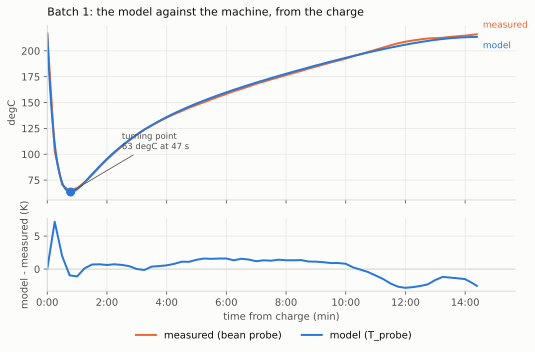

whole curve, 59 samples from the charge -- this page carries the log at 15 s;
the spec checks the same model against all 558 raw samples, at 1.71 K rms
  rms 1.67 K, worst 7.16 K
after 120 s, 51 samples:
  rms 1.44 K, worst 2.85 K
turn: model 63.4 degC at 47 s, measured 64.5 degC at 45 s


In [7]:
b1 = BATCHES[0]
m_t = np.array([p[0] for p in b1["bt"]])
m_bt = np.array([p[1] for p in b1["bt"]])

model = np.array([result.at(float(x))["probe"] for x in m_t])
residual = model - m_bt

fig, (top, bottom) = plt.subplots(
    2, 1, figsize=(8.4, 4.8), sharex=True, height_ratios=[2.4, 1], gridspec_kw={"hspace": 0.15}
)

top.plot(m_t, m_bt, color=ORANGE)
top.plot(t, probe, color=BLUE)
label(top, m_t[-1], m_bt[-1], "measured", ORANGE, dy=9)
label(top, t[-1], probe[-1], "model", BLUE, dy=-9)

turn = int(np.argmin(probe))
top.plot([t[turn]], [probe[turn]], marker="o", markersize=8, color=BLUE, zorder=5)
top.annotate(
    f"turning point\n{probe[turn]:.0f} degC at {t[turn]:.0f} s",
    xy=(t[turn], probe[turn]),
    xytext=(150, 105),
    fontsize=8.5,
    color=MUTED,
    arrowprops={"arrowstyle": "-", "color": MUTED, "linewidth": 0.8},
)
top.set_title("Batch 1: the model against the machine, from the charge")
top.set_ylabel("degC")
top.set_xlim(0, STOP * 1.09)

bottom.axhline(0, color=LINE, linewidth=0.8)
bottom.plot(m_t, residual, color=BLUE)
bottom.set_ylabel("model - measured (K)")
minutes(bottom)

fig.legend(
    handles=[
        mpl.lines.Line2D([], [], color=ORANGE, label="measured (bean probe)"),
        mpl.lines.Line2D([], [], color=BLUE, label="model (T_probe)"),
    ],
    loc="lower center",
    ncol=2,
    bbox_to_anchor=(0.5, -0.06),
)
plt.show()

late = m_t >= SETTLED
print(f"whole curve, {len(m_t)} samples from the charge -- this page carries the log at 15 s;")
print("the spec checks the same model against all 558 raw samples, at 1.67 K rms")
print(f"  rms {np.sqrt((residual**2).mean()):.2f} K, worst {np.abs(residual).max():.2f} K")
print(f"after {SETTLED:.0f} s, {late.sum()} samples:")
print(
    f"  rms {np.sqrt((residual[late] ** 2).mean()):.2f} K, "
    f"worst {np.abs(residual[late]).max():.2f} K"
)
print(
    f"turn: model {probe[turn]:.1f} degC at {t[turn]:.0f} s, "
    f"measured {m_bt.min():.1f} degC at {m_t[int(np.argmin(m_bt))]:.0f} s"
)

## What the roaster is reading is late

Nobody roasting coffee watches the temperature. They watch its slope — *rate of rise*, in
degrees per minute — because that is the thing that has to come down smoothly.

Now that the probe is in the model, there are two rates of rise to compare: the coffee's,
and the one the roaster can actually see. They are not the same, and the gap between the
temperatures behind them is not small. Around two minutes the coffee is running **8 K
ahead** of the number on the display, closing to under a degree by the drop.

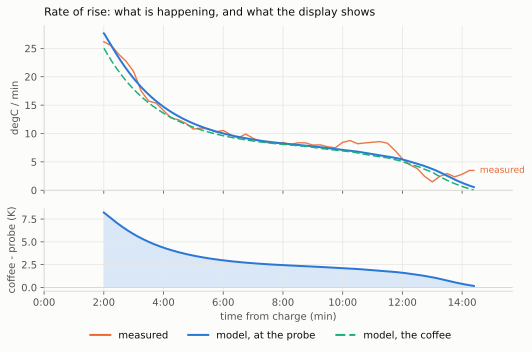

  t =  2.00 min   coffee  103.7   probe   95.5   lag +8.22 K
  t =  5.00 min   coffee  152.5   probe  149.1   lag +3.49 K
  t = 10.00 min   coffee  195.4   probe  193.3   lag +2.11 K
  t = 14.39 min   coffee  213.7   probe  213.5   lag +0.16 K


In [8]:
def rate_of_rise(times, values, after=0.0):
    """Degrees per minute, and the instants it is defined at.

    An event puts two samples at the same instant -- the value on each side of the
    discontinuity, which is the whole point of restarting there -- and a centred difference
    over a zero-width interval is a division by zero. So the duplicates come out first.
    """
    keep = np.concatenate(([True], np.diff(times) > 0)) & (times >= after)
    kept, kept_values = times[keep], values[keep]
    return kept, np.gradient(kept_values, kept) * 60.0


lag = result.values[result.names.index("lag")]

fig, (top, bottom) = plt.subplots(
    2, 1, figsize=(8.4, 4.8), sharex=True, height_ratios=[2, 1], gridspec_kw={"hspace": 0.15}
)

m_ror_t, m_ror = rate_of_rise(m_t, m_bt, after=SETTLED)
p_ror_t, p_ror = rate_of_rise(t, probe, after=SETTLED)
b_ror_t, b_ror = rate_of_rise(t, bean, after=SETTLED)
top.plot(m_ror_t, m_ror, color=ORANGE, linewidth=1.4, alpha=0.9)
top.plot(p_ror_t, p_ror, color=BLUE)
top.plot(b_ror_t, b_ror, color=AQUA, linewidth=1.5, linestyle=(0, (5, 2)))
label(top, m_ror_t[-1], m_ror[-1], "measured", ORANGE)
top.set_title("Rate of rise: what is happening, and what the display shows")
top.set_ylabel("degC / min")
top.set_ylim(0, None)
top.set_xlim(0, STOP * 1.09)

keep = t >= SETTLED
bottom.axhline(0, color=LINE, linewidth=0.8)
bottom.fill_between(t[keep], 0, lag[keep], color=BLUE, alpha=0.16, linewidth=0)
bottom.plot(t[keep], lag[keep], color=BLUE)
bottom.set_ylabel("coffee - probe (K)")
minutes(bottom)

fig.legend(
    handles=[
        mpl.lines.Line2D([], [], color=ORANGE, label="measured"),
        mpl.lines.Line2D([], [], color=BLUE, label="model, at the probe"),
        mpl.lines.Line2D([], [], color=AQUA, linestyle=(0, (5, 2)), label="model, the coffee"),
    ],
    loc="lower center",
    ncol=3,
    bbox_to_anchor=(0.5, -0.06),
)
plt.show()

for x in [120.0, 300.0, 600.0, STOP]:
    s = result.at(x)
    print(
        f"  t = {x / 60:5.2f} min   coffee {s['bean']:6.1f}   probe {s['probe']:6.1f}   "
        f"lag {s['lag']:+5.2f} K"
    )


## One parameter set, five batches

Seven numbers describe the machine, and they were fitted against **all five batches at
once** — 2791 samples — rather than against batch 1 alone. Each batch then keeps three
things of its own: its recorded gas trace, its probe reading at the charge mark, and its
machine temperature at the charge mark.

That third one matters more than it looks, and this notebook got it wrong until recently.
The prose claimed it while `rebound()` rebound only the probe, so every batch was silently
wearing batch 1's preheat — and the residual grew monotonically down the session, about
1.5 K per batch, which is the signature of a state that differs between runs and is being
forced to be the same. `rusty-replicant-32c43` spotted the contradiction between the
sentence and the code.

Batch 1 followed a 35-minute cold-start preheat; batches 2–5 came off a purge-and-reheat
between roasts, where the Loring opens a gate, pulls room air until the drum is down around
77 °C, then closes it and comes back to charge temperature. So the machine really does start
each batch somewhere slightly different, and it is not a drift — it is one cold start
followed by four nearly identical turnarounds.


In [9]:
from dataclasses import replace

from modelica.ir import nodes as ir
from modelica.ir.flat import FlatModel


def rebound(model: FlatModel, steps, probe0: float, mach0: float) -> FlatModel:
    """The same model on a different gas trace, from a different pair of initial readings.

    The schedule lives in the equation for `burner` as a chain of comparisons against
    `time`, so swapping it means rebuilding that chain -- which is what the Python
    front-end does when it folds a table, and what `unparse` prints back as
    `if ... elseif ... else`.

    Level `i` holds from `steps[i][0]` until `steps[i + 1][0]`, so each comparison carries
    the level *before* it, ending on the last level, which has nothing after it to stop it.
    """
    chain: ir.Expr = ir.RealLiteral(float(steps[-1][1]))
    for index in range(len(steps) - 1, 0, -1):
        chain = ir.IfExpr(
            ir.Binary("<", ir.Ref(("time",)), ir.RealLiteral(float(steps[index][0]))),
            ir.RealLiteral(float(steps[index - 1][1])),
            chain,
        )
    starts = {"T_probe": probe0 + 273.15, "T_mach": mach0 + 273.15}
    return replace(
        model,
        equations=tuple(
            replace(eq, rhs=chain)
            if isinstance(eq.lhs, ir.Ref) and eq.lhs.parts == ("burner",)
            else eq
            for eq in model.equations
        ),
        variables=tuple(
            replace(v, start=ir.RealLiteral(starts[v.name])) if v.name in starts else v
            for v in model.variables
        ),
    )


def roast(batch):
    """Run the model against one recorded batch: its gas, its probe, its machine."""
    return simulate(
        causalize(rebound(flat, batch["gas"], batch["bt"][0][1], batch["mach0"])),
        stop=batch["stop"],
        tolerance=1e-10,
        points=700,
    )


runs = [roast(b) for b in BATCHES]

 batch      rms    worst  after 2 min  drop meas    model
     1    1.65K    7.16K        1.42K      216.1    213.6
     2    2.47K    3.90K        2.62K      216.9    218.7
     3    2.60K    4.53K        2.75K      215.7    217.2
     4    3.10K    4.23K        3.29K      215.9    217.7
     5    3.31K    5.53K        3.52K      215.1    220.1


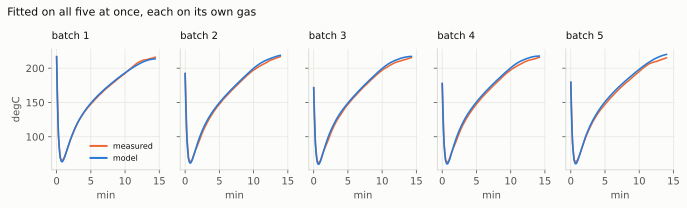


Note what this page cannot show you. It carries the log downsampled to 15 s, and the
worst disagreement on batches 2-4 is in the first second and a half -- where the probe
is still swinging from the previous drop when the charge mark lands, so its start value
is contaminated. Against the full 1.5 s log those batches peak at 9 to 11 K there, and
under 7 K everywhere after. Batch 1 is the only one preceded by a preheat rather than a
drop, which is why the example carries it.


In [10]:
fig, axes = plt.subplots(1, 5, figsize=(9.6, 2.9), sharex=True, sharey=True)

print(
    f"{'batch':>6} {'T_mach(0)':>10} {'rms':>8} {'after 2 min':>12} {'drop meas':>10} {'model':>8}"
)
for n, (ax, b, run) in enumerate(zip(axes, BATCHES, runs, strict=True), 1):
    bt_t = np.array([p[0] for p in b["bt"]])
    bt_v = np.array([p[1] for p in b["bt"]])
    sim = np.array([run.at(float(x))["probe"] for x in bt_t])
    err = sim - bt_v
    late = bt_t >= SETTLED

    ax.plot(bt_t, bt_v, color=ORANGE, linewidth=1.6)
    ax.plot(run.time, run.values[run.names.index("probe")], color=BLUE, linewidth=1.6)
    ax.set_title(f"batch {n}", fontsize=10)
    ax.set_xticks([0, 300, 600, 900])
    ax.xaxis.set_major_formatter(lambda s, _: f"{int(s // 60)}")
    ax.set_xlabel("min")
    if n == 1:
        ax.set_ylabel("degC")

    print(
        f"{n:>6} {b['mach0']:9.1f}C {np.sqrt((err**2).mean()):7.2f}K "
        f"{np.sqrt((err[late] ** 2).mean()):11.2f}K {bt_v[-1]:10.1f} {sim[-1]:8.1f}"
    )

axes[0].legend(
    handles=[
        mpl.lines.Line2D([], [], color=ORANGE, label="measured"),
        mpl.lines.Line2D([], [], color=BLUE, label="model"),
    ],
    loc="lower right",
    fontsize=8,
)
fig.tight_layout()
fig.subplots_adjust(top=0.78)
fig.suptitle(
    "Fitted on all five at once, each on its own gas", x=0.01, y=0.98, ha="left", fontsize=11
)
plt.show()

print()
print("The residual no longer grows down the session -- and batch 1 is now the *worst* of")
print("the five rather than the best, which is what you would expect once every batch stops")
print("wearing its preheat. This page carries the log at 15 s, so it cannot show the one")
print("place the model still misses badly: the first second or two of batches 2-4, where")
print("the probe is still swinging from the previous drop when the charge mark lands.")


## The knobs a roaster actually has

Four of them, and all four are parameters of the flat model, so tuning them is
`dataclasses.replace` and a re-causalization — the same trick as
[Turning the knobs](exploring.ipynb).

* **charge** is `m_green`. The measured charge is 13.8 kg, not the machine's rated 15, and
  because `m_dry` and the starting water are computed from it, changing it moves the heat
  capacity *and* the mass balance.
* **moisture** is the fraction of that charge which is water.
* **preheat** is where the machine starts — the number that separates batch 1 from the
  four that follow it.
* **gas trim** scales `Q_max`, standing in for a different line pressure or a dirtier
  burner.

The readout is what a roaster cares about: how hot it was when it came out, how long it took
to reach 196 °C — about where first crack starts, and the recorded batch hit it at 11:25 —
and how much of the charge left as steam.


In [11]:
def tuned(model: FlatModel, values: dict, preheat: float | None = None) -> FlatModel:
    """A copy with those parameters rebound, and optionally a different preheat.

    `m_dry` and the initial water are *bindings over other parameters* rather than
    literals, so rebinding `m_green` or `moisture` carries through to both of them without
    anything here having to know that it should.
    """
    unknown = set(values) - {v.name for v in model.variables}
    if unknown:
        raise KeyError(f"{model.name} has no {sorted(unknown)}")
    return replace(
        model,
        variables=tuple(
            replace(
                v,
                binding=ir.RealLiteral(float(values[v.name])) if v.name in values else v.binding,
                start=(
                    ir.RealLiteral(preheat + 273.15)
                    if preheat is not None and v.name == "T_mach"
                    else v.start
                ),
            )
            for v in model.variables
        ),
    )


def crack(run, threshold: float = 196.0) -> float | None:
    """When the probe first reads `threshold`, interpolated between output points."""
    times = run.time
    reading = run.values[run.names.index("probe")]
    hit = np.flatnonzero(reading >= threshold)
    if not len(hit):
        return None
    k = int(hit[0])
    if k == 0:
        return float(times[0])
    lo, hi = reading[k - 1], reading[k]
    return float(times[k - 1] + (threshold - lo) / (hi - lo) * (times[k] - times[k - 1]))

In [12]:
import ipywidgets as widgets


def show(charge: float, moisture: float, preheat: float, trim: float) -> None:
    run = simulate(
        causalize(
            tuned(
                flat,
                {"m_green": charge, "moisture": moisture, "Q_max": 1.32e5 * trim},
                preheat=preheat,
            )
        ),
        stop=STOP,
        tolerance=1e-9,
        points=700,
    )
    reading = run.values[run.names.index("probe")]
    fc = crack(run)

    fig, ax = plt.subplots(figsize=(8.4, 3.4))
    ax.plot(m_t, m_bt, color=ORANGE, linewidth=1.4)
    ax.plot(run.time, reading, color=BLUE)
    label(ax, m_t[-1], m_bt[-1], "as roasted", ORANGE, dy=9)
    label(ax, run.time[-1], reading[-1], "this batch", BLUE, dy=-9)
    if fc is not None:
        ax.plot([fc], [196.0], marker="o", markersize=8, color=BLUE, zorder=5)
        ax.axhline(196.0, color=LINE, linewidth=0.8, zorder=0)

    end = run.at(STOP)
    when = f"{fc / 60:.2f} min" if fc is not None else "never"
    ax.set_title(
        f"drop {end['probe']:.1f} degC   ·   196 degC at {when}   ·   "
        f"{end['loss']:.2f} % lost as steam"
    )
    ax.set_ylabel("degC")
    ax.set_ylim(0, 260)
    ax.set_xlim(0, STOP * 1.09)
    minutes(ax)
    ax.legend(
        handles=[
            mpl.lines.Line2D([], [], color=ORANGE, label="batch 1, as roasted"),
            mpl.lines.Line2D([], [], color=BLUE, label="model, with these knobs"),
        ],
        loc="lower right",
    )
    plt.show()


widgets.interact(
    show,
    charge=widgets.FloatSlider(value=13.8, min=8.0, max=18.0, step=0.2, description="charge (kg)"),
    moisture=widgets.FloatSlider(
        value=0.13, min=0.07, max=0.18, step=0.005, readout_format=".3f", description="moisture"
    ),
    preheat=widgets.FloatSlider(
        value=237.4, min=200.0, max=270.0, step=1.0, description="preheat (degC)"
    ),
    trim=widgets.FloatSlider(value=1.0, min=0.7, max=1.3, step=0.02, description="gas trim"),
)

interactive(children=(FloatSlider(value=15.0, description='charge (kg)', max=18.0, min=8.0, step=0.5), FloatSl…

<function __main__.show(charge: float, moisture: float, preheat: float, trim: float) -> None>


## What the weighing changed

When this notebook was first written it ended with a paragraph asking for one number: the
weight of a batch, green in and roasted out. It arrived — off a screen recording of the
roaster's own session, same four batches:

| | green | roasted | lost |
|---|---|---|---|
| PR-1913 | 13.8 kg | 11.76 kg | 14.78 % |
| PR-1914 | 13.8 kg | 11.74 kg | 14.93 % |
| PR-1915 | 13.8 kg | 11.76 kg | 14.78 % |
| PR-1916 | 13.8 kg | 11.73 kg | 15.00 % |

Two things fell out of it, and the second is the interesting one.

**The charge was 13.8 kg, not 15.** The model had been using the machine's *rated* capacity
because the bridge capture carried no weight — a rated capacity is not a charge, and that
alone was an 8 % error in the heat capacity of everything.

**The drying law was wrong, not merely mistuned.** The old model gated evaporation at
100 °C, on the reasoning that water leaves when water boils, and removed 2.7 % of the charge
where ~11 points of water should go. Forced to remove the right mass it fell apart entirely.
Sweeping the onset downward fixes the fit and the mass balance *together*, monotonically,
all the way down to ambient:

| onset | curve rms | water lost | dried by half-time |
|---|---|---|---|
| 100 °C | 1.806 K | 11.24 % | 38.7 % |
| 60 °C | 1.492 K | 11.27 % | 51.9 % |
| 40 °C | 1.373 K | 11.37 % | 58.1 % |
| 20 °C | 1.232 K | 11.41 % | 64.3 % |

A coffee bean is not a puddle. It is porous, and it gives up bound water by diffusion the
whole time it is warm — which is why roasters call the *first* third of a roast the drying
phase. `T_dry = 40 °C` is a modelling choice costing 0.14 K against no threshold at all; it
keeps the crossing a real event instead of one that fires at `t = 0` and means nothing.

**How this was nearly missed.** Sweeping the drying with the seven machine parameters held
fixed, *no* combination reproduces both the curve and the mass — and the obvious reading is
that a term is missing, with first crack being genuinely exothermic making that a tempting
one to reach for. But those seven had been fitted against a model whose latent sink was four
times too small, so `UA`, `G_loss` and `Q_max` had already absorbed the missing heat. Adding
it back on top of them cannot work. Refitting everything together is what showed the shape
had been fine all along.

## What is still assumed

`moisture` is still a parameter, not a measurement. The weighing gives *total* loss, and a
roast also sheds dry matter — CO2, volatiles, chaff, three or four points of it — which this
model has no term for. So the water target is the measured 14.87 % less an assumed 3.5 %
organic loss, and that 3.5 % is now the softest number in the whole example. A green
moisture meter would turn both it and `moisture` into one measurement and one residual.

The rest, and the measured points these figures are drawn against, is in
[`RoastingMachine.toml`](https://gitlab.com/cardona-oss/modelica/-/blob/main/examples/models/RoastingMachine.toml).
